# MPI-Live-Demo zur Wärmeausbreitung

Führe beide Codezellen auf dem Ubuntu-Manager aus, wenn kein Messfenster reserviert ist. Die Demo nutzt Open MPI und die Python-Umgebung `/home/itmvs/venv` mit NumPy, Numba und mpi4py. Der Notebook-Kernel braucht NumPy, Matplotlib und IPython.

Links siehst du die Temperatur während der laufenden Berechnung. Rechts zeigen die Farben, welcher Rang die jeweilige Zelle berechnet. Grau markiert die festen Randzellen. Die Pause zwischen Zwischenständen ist eine reine Demo-Funktion.

Mit **Kernel → Unterbrechen** kannst du die Demo stoppen. Das Notebook beendet dann den MPI-Launcher und räumt den temporären Ordner auf. Nach einem vollständigen Lauf vergleicht es Schritt 500 mit dem vorhandenen C3-Ergebnis.

In [1]:
import os
import signal
import subprocess
import time
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.colors import BoundaryNorm, ListedColormap


def erstelle_abbildung(temperatur, raenge):
    fig, (links, rechts) = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
    waermebild = links.imshow(
        temperatur, cmap="inferno", vmin=0, vmax=100, origin="upper", interpolation="nearest"
    )
    titel = links.set_title("")
    fig.colorbar(waermebild, ax=links, label="Temperatur", ticks=[0, 25, 50, 75, 100])

    farben = ListedColormap(["#dddddd", "#4477aa", "#66ccee", "#228833", "#cc6677"])
    rangbild = rechts.imshow(
        raenge, cmap=farben, norm=BoundaryNorm(np.arange(-1.5, 4), farben.N),
        origin="upper", interpolation="nearest",
    )
    rechts.set_title("Berechnete Zellen je MPI-Rang")
    legende = fig.colorbar(rangbild, ax=rechts, ticks=[-1, 0, 1, 2, 3])
    legende.ax.set_yticklabels(["Rand", "Rang 0", "Rang 1", "Rang 2", "Rang 3"])
    for achse in (links, rechts):
        achse.set_axis_off()

    # Das Notebook zeigt nur die Bilder, die wir gezielt aktualisieren.
    plt.close(fig)
    return fig, waermebild, titel


def beende_mpi(prozess):
    if prozess.poll() is not None:
        return
    # Open MPI erhält zuerst Zeit, die lokalen Ränge selbst zu beenden.
    prozess.terminate()
    try:
        prozess.wait(timeout=8)
    except subprocess.TimeoutExpired:
        try:
            os.killpg(prozess.pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
        prozess.wait()


def vergleiche_schritt_500(ausgabe, projekt):
    zwischenstand = ausgabe / "gitter_S00500.npy"
    referenz = projekt / "gitter_N128_P4_S500.npy"
    if not zwischenstand.is_file() or not referenz.is_file():
        print("Vergleich für Schritt 500 offen. Es fehlt ein Zwischenstand oder die C3-Referenz.")
        return

    live = np.load(zwischenstand, allow_pickle=False)
    c3 = np.load(referenz, allow_pickle=False)
    if live.shape != (128, 128) or c3.shape != live.shape:
        raise ValueError(f"Vergleich erwartet zwei 128 × 128-Gitter. Formen: {live.shape}, {c3.shape}")

    abweichung = np.max(np.abs(live - c3))
    print(f"Schritt 500: maximale absolute Temperaturabweichung zu C3 = {abweichung:.12g}")
    if not np.isfinite(abweichung) or abweichung > 1e-12:
        raise ValueError("Die maximale Temperaturabweichung überschreitet die Toleranz von 1e-12.")


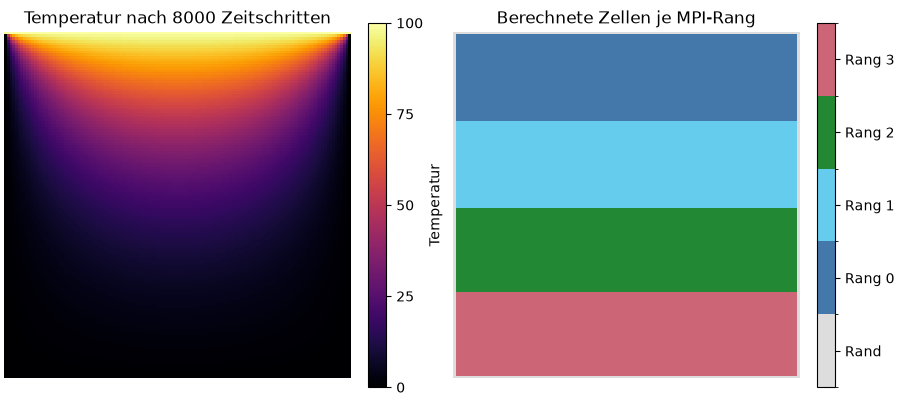

Schritt 500: maximale absolute Temperaturabweichung zu C3 = 0


In [3]:
projekt = Path("/home/itmvs/waerme/niklas")
mpi_python = Path("/home/itmvs/venv/bin/python")
schritte = 8000
intervall = 50
demo_pause = 0.15  # Sekunden je Zwischenstand, nur zur Live-Anzeige

with TemporaryDirectory(prefix="waerme-live-") as temp:
    ausgabe = Path(temp)
    protokoll = ausgabe / "mpi.log"
    befehl = [
        "mpirun", "--host", "localhost:4", "-np", "4",
        str(mpi_python), "-u", "-m", "mpi4py", str(projekt / "heat_live_mpi.py"),
        str(ausgabe), "--schritte", str(schritte), "--intervall", str(intervall),
        "--demo-pause", str(demo_pause),
    ]

    letzter_schritt = -1
    anzeige = None
    with protokoll.open("w", encoding="utf-8") as log:
        prozess = subprocess.Popen(
            befehl, cwd=projekt, stdout=log, stderr=subprocess.STDOUT, start_new_session=True
        )
        try:
            while True:
                # Nach einem Prozessende noch einmal alle publizierten Dateien erfassen.
                status = prozess.poll()
                neuester_schritt = max(
                    (int(datei.stem.split("_S", 1)[1]) for datei in ausgabe.glob("gitter_S*.npy")),
                    default=-1,
                )
                if neuester_schritt > letzter_schritt:
                    temperatur = np.load(
                        ausgabe / f"gitter_S{neuester_schritt:05d}.npy", allow_pickle=False
                    )
                    if anzeige is None:
                        raenge = np.load(ausgabe / "raenge.npy", allow_pickle=False)
                        fig, waermebild, titel = erstelle_abbildung(temperatur, raenge)
                    else:
                        waermebild.set_data(temperatur)
                    titel.set_text(f"Temperatur nach {neuester_schritt} Zeitschritten")

                    with BytesIO() as bildpuffer:
                        fig.savefig(bildpuffer, format="png", dpi=100)
                        ausgabebild = Image(data=bildpuffer.getvalue())
                    if anzeige is None:
                        anzeige = display(ausgabebild, display_id=True)
                    else:
                        anzeige.update(ausgabebild)
                    letzter_schritt = neuester_schritt

                if status is not None:
                    break
                time.sleep(0.08)
        finally:
            beende_mpi(prozess)

    if status != 0:
        meldung = protokoll.read_text(encoding="utf-8", errors="replace").strip()
        raise RuntimeError(f"MPI-Demo beendet mit Status {status}.\n{meldung}")
    if letzter_schritt != schritte:
        raise RuntimeError(f"Letzter geladener Schritt: {letzter_schritt}, erwartet: {schritte}.")

    vergleiche_schritt_500(ausgabe, projekt)
